In [1]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 1000 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.5 * nS 
g_AMPA_rec_E = 5.5 * nS 
g_AMPA_ext_I = 5.5 * nS
g_AMPA_rec_I = 5.5 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

recurrent_radius = 2  


def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,input_freq=40):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    V_thr_E : volt
    tau_rp_E_var : second
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr_E', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory='tau_rp_E_var', method='euler',name='P_E')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.35  
    P_E.k_GABA_E_hsp = 0.35  
    P_E.tau_ins_AMPA_E = tau_ins_AMPA   #50'000
    P_E.tau_int_AMPA_E = tau_int_AMPA   #5'000
    P_E.tau_ins_GABA_E = tau_ins_GABA   
    P_E.tau_int_GABA_E = tau_int_GABA  
    P_E.V_thr_E = V_thr
    P_E.tau_rp_E_var = tau_rp_E

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler',name='P_I')
    P_I.v = V_L


    pg_inp = PoissonGroup(N_inp, rates=input_freq * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    
    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)



    C_PG_E.w[:] = 1.1 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.52, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.9#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I Na blocker so 0.40 to 38
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E Na blocker so 0.32 to 0.3


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

   
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')

    r_est_mon = StateMonitor(P_E, variables=['r_est'], record=[45], name = 'r_est',dt=record_dt)

    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



# def show_rand_rate(net, show_time = 1000*ms):
#     N_inp=net['inp'].N
#     rates = np.random.normal(loc=40, scale=0, size=N_inp)
#     rate_img = np.clip(rates, 5, 50)*Hz
#     net['inp'].rates = rate_img
#     net.run(show_time, report = 'text')



def run_sim(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,input_freq=40,show_time = 1000*ms):
    net = build_network(tau_ins_AMPA=tau_ins_AMPA,tau_int_AMPA=tau_int_AMPA,tau_ins_GABA=tau_ins_GABA,tau_int_GABA=tau_int_GABA,input_freq=input_freq)
    net.run(show_time, report = 'text')
    # show_rand_rate(net,show_time=show_time)
    return net



INFO       Cache size for target 'cython': 2306 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


In [2]:
start_scope()
seed(123)
defaultclock.dt = 1000 * us
net = run_sim(tau_ins_AMPA=50*second,
              tau_int_AMPA=50*second,
              tau_ins_GABA=50*second,
              tau_int_GABA=50*second,
              show_time=15000*second)

INFO:root:creating /tmp/brian_flag_test_adway4vp/tmp
INFO:root:creating /tmp/brian_flag_test_adway4vp/tmp/brian_flag_test_adway4vp
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_adway4vp/flag_test.cpp -o /tmp/brian_flag_test_adway4vp/tmp/brian_flag_test_adway4vp/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_x8peg6a9/tmp
INFO:root:creating /tmp/brian_flag_test_x8peg6a9/tmp/brian_flag_test_x8peg6a9
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_x8peg6a9/flag_test.cpp -o /tmp/brian_flag_test_x8peg6a9/tmp/brian_flag_test_x8peg6a9/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_db4oxwt6/tmp
INFO:root:creating /tmp/brian_flag_test_db4oxwt6/tmp/brian_flag_test_db4oxwt6
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_db4oxwt6/flag_test.cpp -o /tmp/brian_flag_test_db

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Starting simulation at t=0. s for a duration of 15. ks
169.261 s (1%) simulated in 10s, estimated 14m 36s remaining.
0.336685 ks (2%) simulated in 20s, estimated 14m 31s remaining.
0.507099 ks (3%) simulated in 30s, estimated 14m 17s remaining.
0.676453 ks (4%) simulated in 40s, estimated 14m 7s remaining.
0.84402 ks (5%) simulated in 50s, estimated 13m 59s remaining.
1.015531 ks (6%) simulated in 1m 0s, estimated 13m 46s remaining.
1.185601 ks (7%) simulated in 1m 10s, estimated 13m 36s remaining.
1.35387 ks (9%) simulated in 1m 20s, estimated 13m 26s remaining.
1.524021 ks (10%) simulated in 1m 30s, estimated 13m 16s remaining.
1.696253 ks (11%) simulated in 1m 40s, estimated 13m 4s remaining.
1.866401 ks (12%) simulated in 1m 50s, estimated 12m 54s remaining.
2.041126 ks (13%) simulated in 2m 0s, estimated 12m 42s remaining.
2.217169 ks (14%) simulated in 2m 10s, estimated 12m 30s remaining.
2.391076 

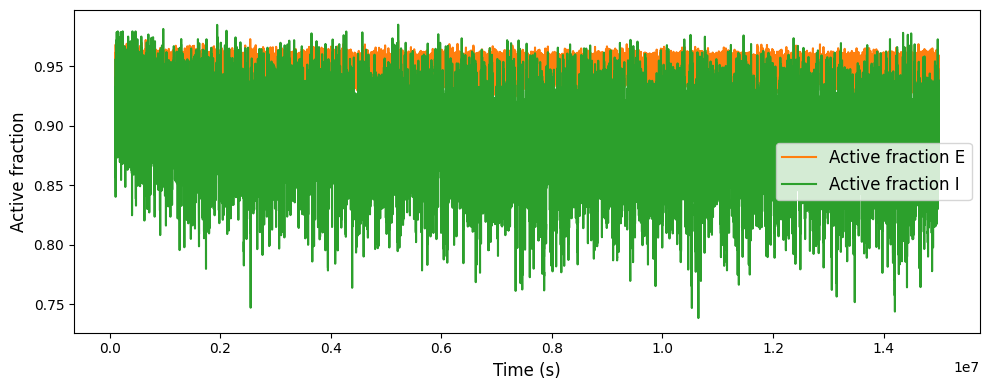

In [3]:
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']

plt.figure(figsize=(10, 4))
plt.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction E')
plt.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction I')
plt.xlabel('Time (s)',fontsize=12)
plt.ylabel('Active fraction',fontsize=12)
plt.legend(loc=5,fontsize=12)
plt.tight_layout()

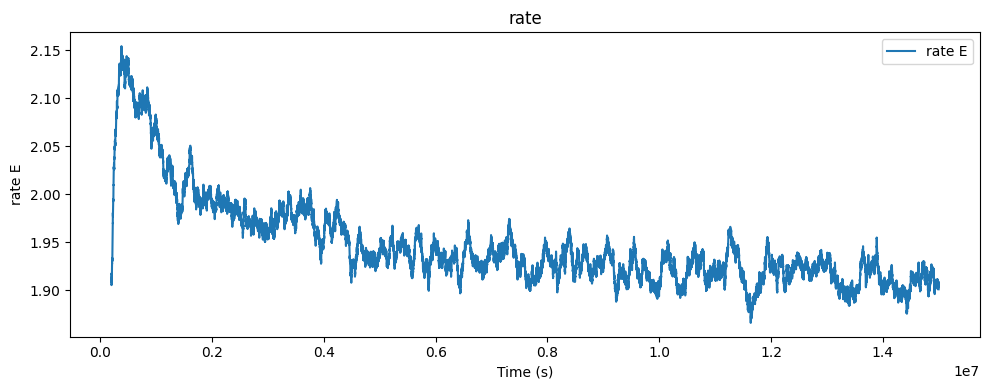

In [4]:
r_est_E = net['rate_pop_mon_E']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[1000:]/ms, r_est_E.r_pop_E[0,1000:]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

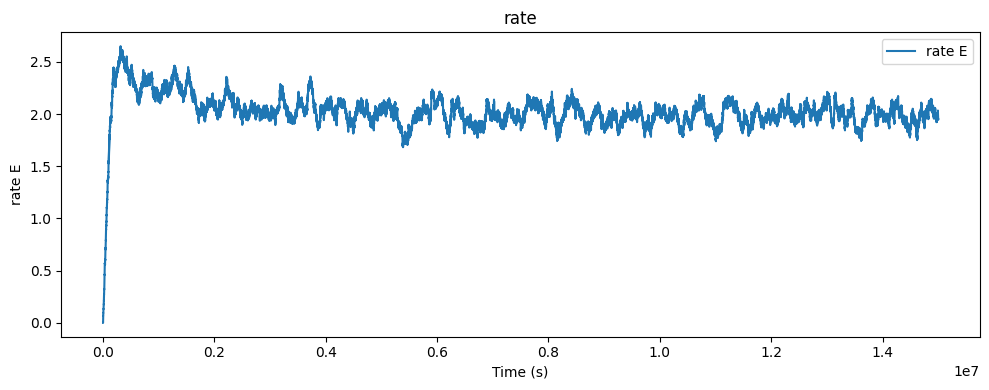

In [5]:
r_est_E = net['r_est']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t/ms, r_est_E.r_est[0]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

In [ ]:
kAMPA_mon_E=net['k_AMPA_E_hsp']
kGABA_mon_E=net['k_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(kAMPA_mon_E.t/second, kAMPA_mon_E.k_AMPA_E_hsp[45], label='AMPA',color='tab:orange',linestyle=':',linewidth=2)
plt.plot(kGABA_mon_E.t/second, kGABA_mon_E.k_GABA_E_hsp[45], label='GABA',color='tab:green',linestyle=':',linewidth=2)
plt.xlabel('Time (s)',fontsize=12)
plt.ylabel('k HSP(t)',fontsize=12)
#plt.title('Homeostatic Synaptic Scaling')
plt.legend(loc=5,fontsize=12)
plt.tight_layout()

In [ ]:
#net.store('baseline',filename='baseline_2hz.bri')

## first run 0s

In [7]:
start_scope()
seed(123)
net = run_sim(tau_ins_AMPA=50*second,
              tau_int_AMPA=50*second,
              tau_ins_GABA=50*second,
              tau_int_GABA=50*second,
              show_time=0*second)

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


In [8]:
net.restore('baseline', filename='baseline_2hz.bri')

# IPC

In [3]:
import numpy as np, matplotlib.pyplot as plt
import importlib, hsp_capacity, HSP_Phase
importlib.reload(hsp_capacity)
importlib.reload(HSP_Phase)
from HSP_Phase import (characterize_cycle, phase_resolved_capacity,
                       intervention_comparison)

AMP_STAR = 8.0        # from the amplitude calibration
STEP_S   = 0.05

import hsp_metrics, hsp_capacity
print('metrics  :', bool(getattr(hsp_metrics,  '_MODEL_NS', None)))
print('capacity :', bool(getattr(hsp_capacity, '_MODEL_NS', None)))

metrics  : False
capacity : False


In [4]:
import hsp_capacity, HSP_Phase
print(HSP_Phase.capacity_report.__module__)      # 'hsp_capacity'
print(hsp_capacity.capacity_report is HSP_Phase.capacity_report)  # True
import inspect
print('ridges' in inspect.signature(hsp_capacity.capacity_report).parameters)  # True (new)
print('_oof_capacity' in dir(hsp_capacity))      # True (new helper exists)

hsp_capacity
True
True
True


does HSP keep IPC up across the cycle?

bursting=True  period=1773s  recovery=196s  cycle power=38.73
phase           IPC  linMC  multiI     E     I   E/I   power    kA    kG stable
post_ictal     0.05   0.05    0.00  0.93  0.06 16.67   0.001  0.21  0.79   True
mid            0.08   0.08    0.01  1.04  0.15  6.86   0.000  0.60  0.40   True
pre_ictal      0.11   0.09    0.06  1.21  0.56  2.15   0.000  0.91  0.09   True


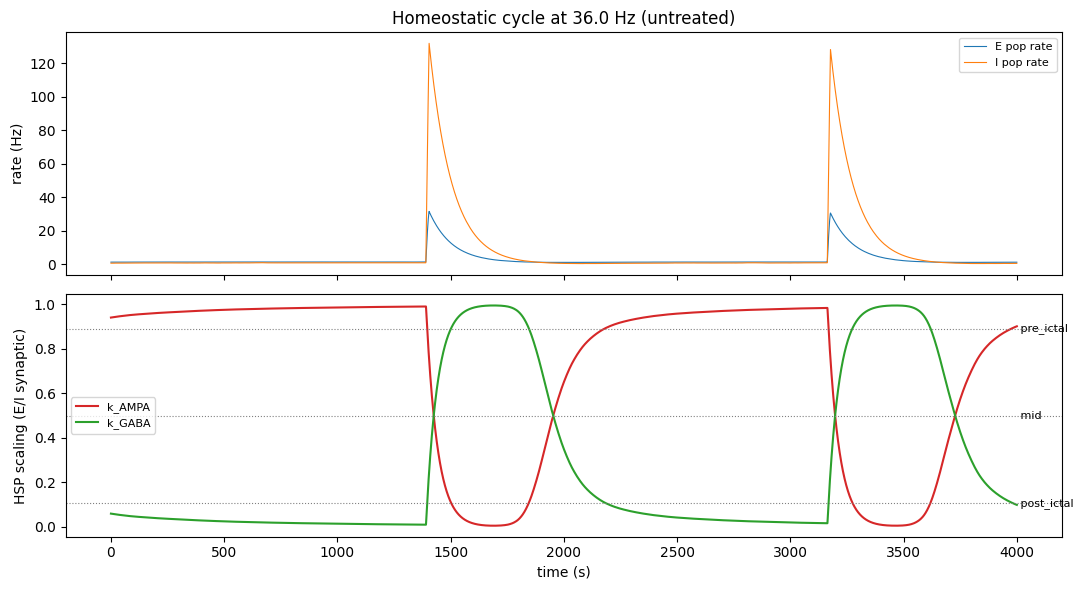

In [22]:
f_seizure = 36.0      
prc = phase_resolved_capacity(net, f_seizure, drug={}, amp_hz=AMP_STAR,
                              step_s=STEP_S, n_steps=2000)

cyc = prc["cycle"]
print(f"bursting={cyc['is_bursting']}  period={cyc['period_s']:.0f}s  "
      f"recovery={cyc['recovery_s']:.0f}s  cycle power={cyc['cycle_lf_power']:.2f}")
print(f"{'phase':12}{'IPC':>7}{'linMC':>7}{'multiI':>8}{'E':>6}{'I':>6}"
      f"{'E/I':>6}{'power':>8}{'kA':>6}{'kG':>6}{'stable':>7}")
for r in prc["rows"]:
    if not r.get("found"):
        print(f"{r['phase']:12} (not found: {r.get('status')})"); continue
    print(f"{r['phase']:12}{r['ipc_total']:7.2f}{r['linear_mc']:7.2f}"
          f"{r['multi_information']:8.2f}{r['E_rate']:6.2f}{r['I_rate']:6.2f}"
          f"{r['EI_ratio']:6.2f}{r['rest_power']:8.3f}{r['k_AMPA']:6.2f}"
          f"{r['k_GABA']:6.2f}{str(not r['burst_during_probe']):>7}")

# cycle trace with the three snapshot phases marked on k_AMPA
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(cyc["t"], cyc["rE"], color="tab:blue", lw=.8, label="E pop rate")
ax[0].plot(cyc["t"], cyc["rI"], color="tab:orange", lw=.8, label="I pop rate")
ax[0].set_ylabel("rate (Hz)"); ax[0].legend(fontsize=8); ax[0].set_title(
    f"Homeostatic cycle at {f_seizure} Hz (untreated)")
ax[1].plot(cyc["t"], cyc["k_AMPA"], color="tab:red", label="k_AMPA")
ax[1].plot(cyc["t"], cyc["k_GABA"], color="tab:green", label="k_GABA")
for r in prc["rows"]:
    if r.get("found"):
        ax[1].axhline(r["k_target"], ls=":", color="0.5", lw=.8)
        ax[1].text(cyc["t"][-1], r["k_target"], " "+r["phase"], fontsize=8, va="center")
ax[1].set_ylabel("HSP scaling (E/I synaptic)"); ax[1].set_xlabel("time (s)")
ax[1].legend(fontsize=8); fig.tight_layout(); plt.show()

Steady state

bursting=False  period=nans  recovery=nans  cycle power=0.01
phase           IPC  linMC  multiI     E     I   E/I   power    kA    kG stable
steady         0.12   0.11    0.05  1.92  1.90  1.01   0.000  0.75  0.22   True


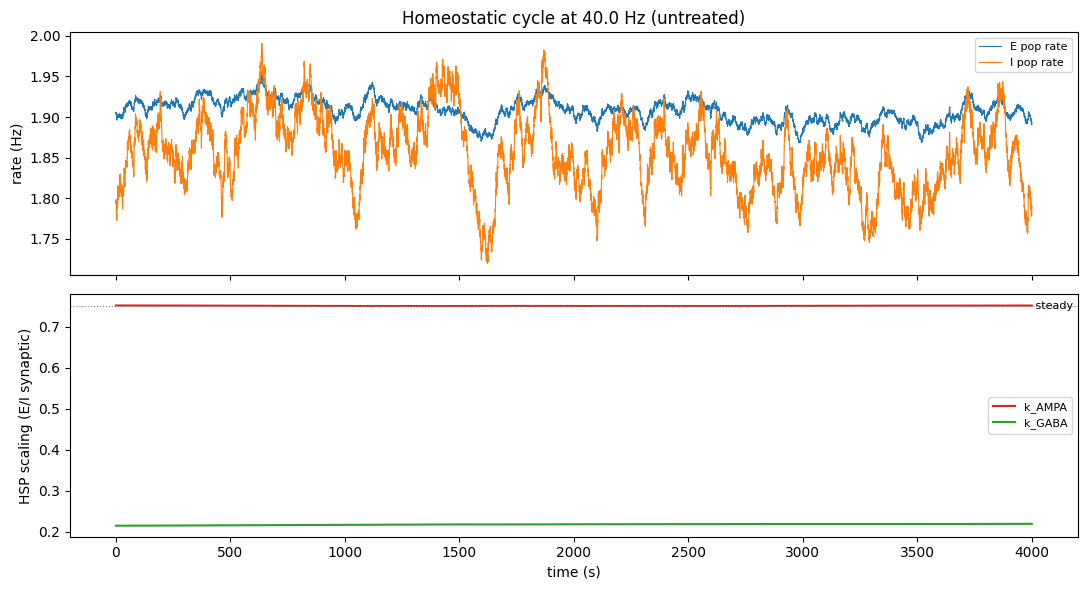

In [23]:
f_seizure = 40.0     
prc = phase_resolved_capacity(net, f_seizure, drug={}, amp_hz=AMP_STAR,
                              step_s=STEP_S, n_steps=2000)

cyc = prc["cycle"]
print(f"bursting={cyc['is_bursting']}  period={cyc['period_s']:.0f}s  "
      f"recovery={cyc['recovery_s']:.0f}s  cycle power={cyc['cycle_lf_power']:.2f}")
print(f"{'phase':12}{'IPC':>7}{'linMC':>7}{'multiI':>8}{'E':>6}{'I':>6}"
      f"{'E/I':>6}{'power':>8}{'kA':>6}{'kG':>6}{'stable':>7}")
for r in prc["rows"]:
    if not r.get("found"):
        print(f"{r['phase']:12} (not found: {r.get('status')})"); continue
    print(f"{r['phase']:12}{r['ipc_total']:7.2f}{r['linear_mc']:7.2f}"
          f"{r['multi_information']:8.2f}{r['E_rate']:6.2f}{r['I_rate']:6.2f}"
          f"{r['EI_ratio']:6.2f}{r['rest_power']:8.3f}{r['k_AMPA']:6.2f}"
          f"{r['k_GABA']:6.2f}{str(not r['burst_during_probe']):>7}")

# cycle trace with the three snapshot phases marked on k_AMPA
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(cyc["t"], cyc["rE"], color="tab:blue", lw=.8, label="E pop rate")
ax[0].plot(cyc["t"], cyc["rI"], color="tab:orange", lw=.8, label="I pop rate")
ax[0].set_ylabel("rate (Hz)"); ax[0].legend(fontsize=8); ax[0].set_title(
    f"Homeostatic cycle at {f_seizure} Hz (untreated)")
ax[1].plot(cyc["t"], cyc["k_AMPA"], color="tab:red", label="k_AMPA")
ax[1].plot(cyc["t"], cyc["k_GABA"], color="tab:green", label="k_GABA")
for r in prc["rows"]:
    if r.get("found"):
        ax[1].axhline(r["k_target"], ls=":", color="0.5", lw=.8)
        ax[1].text(cyc["t"][-1], r["k_target"], " "+r["phase"], fontsize=8, va="center")
ax[1].set_ylabel("HSP scaling (E/I synaptic)"); ax[1].set_xlabel("time (s)")
ax[1].legend(fontsize=8); fig.tight_layout(); plt.show()

### Seed average

In [10]:
import importlib, hsp_capacity, HSP_Phase
importlib.reload(hsp_capacity); importlib.reload(HSP_Phase)   # leaf first

seeds = [11, 22, 33, 44, 55, 66, 77, 88, 99, 111]   # 10 paired input seeds
res = HSP_Phase.run_phase_replication(net, seeds,
                                      burst_freq_hz=36.0, steady_freq_hz=40.0)

for ph, s in res["stats"]["per_phase"].items():
    print(f"{ph:11s}  IPC {s['mean']:.3f}  SD {s['sd']:.3f}  "
          f"95%CI [{s['lo']:.3f}, {s['hi']:.3f}]  n={s['n']}")
print()
for name, c in res["stats"]["contrasts"].items():
    print(f"{name:20s}  Δ {c['mean_diff']:+.3f}  95%CI [{c['lo']:+.3f}, "
          f"{c['hi']:+.3f}]  p_t={c['p_ttest']:.3f}  p_w={c['p_wilcoxon']:.3f}")

post_ictal   IPC 0.089  SD 0.016  95%CI [0.078, 0.100]  n=10
mid          IPC 0.114  SD 0.018  95%CI [0.101, 0.127]  n=10
pre_ictal    IPC 0.138  SD 0.047  95%CI [0.104, 0.172]  n=10
steady       IPC 0.153  SD 0.025  95%CI [0.135, 0.171]  n=10

mid-post_ictal        Δ +0.024  95%CI [+0.010, +0.039]  p_t=0.005  p_w=0.004
pre_ictal-mid         Δ +0.024  95%CI [-0.018, +0.066]  p_t=0.228  p_w=0.084
pre_ictal-steady      Δ -0.015  95%CI [-0.054, +0.024]  p_t=0.404  p_w=1.000


### Benzo

INFO:numexpr.utils:NumExpr defaulting to 16 threads.


bursting=False  period=nans  recovery=nans  cycle power=0.01
phase           IPC  linMC  multiI     E     I   E/I   power    kA    kG stable
steady         0.16   0.12    0.12  1.27  0.70  1.82   0.000  1.00  1.00   True


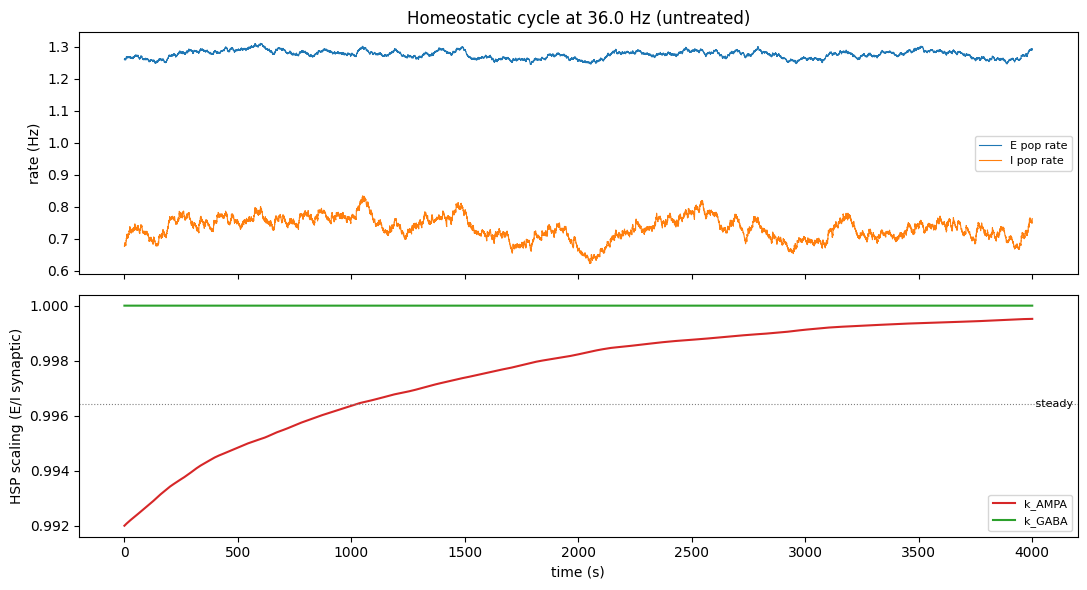

In [ ]:
f_seizure = 36.0
prc = phase_resolved_capacity(net, f_seizure,
                              drug={'benzo': True, 'benzo_kGABA': 1.0},
                              amp_hz=AMP_STAR, step_s=STEP_S, n_steps=2000)

cyc = prc["cycle"]
print(f"bursting={cyc['is_bursting']}  period={cyc['period_s']:.0f}s  "
      f"recovery={cyc['recovery_s']:.0f}s  cycle power={cyc['cycle_lf_power']:.2f}")
print(f"{'phase':12}{'IPC':>7}{'linMC':>7}{'multiI':>8}{'E':>6}{'I':>6}"
      f"{'E/I':>6}{'power':>8}{'kA':>6}{'kG':>6}{'stable':>7}")
for r in prc["rows"]:
    if not r.get("found"):
        print(f"{r['phase']:12} (not found: {r.get('status')})"); continue
    print(f"{r['phase']:12}{r['ipc_total']:7.2f}{r['linear_mc']:7.2f}"
          f"{r['multi_information']:8.2f}{r['E_rate']:6.2f}{r['I_rate']:6.2f}"
          f"{r['EI_ratio']:6.2f}{r['rest_power']:8.3f}{r['k_AMPA']:6.2f}"
          f"{r['k_GABA']:6.2f}{str(not r['burst_during_probe']):>7}")

# cycle trace with the three snapshot phases marked on k_AMPA
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(cyc["t"], cyc["rE"], color="tab:blue", lw=.8, label="E pop rate")
ax[0].plot(cyc["t"], cyc["rI"], color="tab:orange", lw=.8, label="I pop rate")
ax[0].set_ylabel("rate (Hz)"); ax[0].legend(fontsize=8); ax[0].set_title(
    f"Homeostatic cycle at {f_seizure} Hz (treated)")
ax[1].plot(cyc["t"], cyc["k_AMPA"], color="tab:red", label="k_AMPA")
ax[1].plot(cyc["t"], cyc["k_GABA"], color="tab:green", label="k_GABA")
for r in prc["rows"]:
    if r.get("found"):
        ax[1].axhline(r["k_target"], ls=":", color="0.5", lw=.8)
        ax[1].text(cyc["t"][-1], r["k_target"], " "+r["phase"], fontsize=8, va="center")
ax[1].set_ylabel("HSP scaling (E/I synaptic)"); ax[1].set_xlabel("time (s)")
ax[1].legend(fontsize=8); fig.tight_layout(); plt.show()

In [9]:
seeds = [11, 22, 33, 44, 55, 66, 77, 88, 99, 111]   # 10 paired input seeds , 33, 44, 55, 66, 77, 88, 99, 111

res_ctrl  = HSP_Phase.run_phase_replication(net, seeds, burst_freq_hz=36.0,
                                            steady_freq_hz=40.0)
res_benzo = HSP_Phase.run_phase_replication(net, seeds, burst_freq_hz=36.0,
                                            steady_freq_hz=40.0,
                                            drug={'benzo': True, 'benzo_kGABA': 1.0})

In [10]:
merged = {f"ctrl_{k}": v for k, v in res_ctrl["by_phase"].items()}
merged.update({f"benzo_{k}": v for k, v in res_benzo["by_phase"].items()})
st = HSP_Phase.paired_phase_stats(
        merged, metric="ipc_total",
        contrasts=[("benzo_mid", "ctrl_mid"),          # or benzo_steady vs ctrl_mid
                   ("benzo_pre_ictal", "ctrl_pre_ictal")])

In [11]:
print(st)

{'per_phase': {'ctrl_post_ictal': {'n': 10, 'mean': 0.08922154542528027, 'sd': 0.015733745287544218, 'sem': 0.004975447123358059, 'lo': 0.07796630207733678, 'hi': 0.10047678877322376}, 'ctrl_mid': {'n': 10, 'mean': 0.11370371943273008, 'sd': 0.018285430678680742, 'sem': 0.0057823608941749635, 'lo': 0.10062311031841878, 'hi': 0.12678432854704139}, 'ctrl_pre_ictal': {'n': 10, 'mean': 0.13761018225707972, 'sd': 0.04737722937586815, 'sem': 0.014981995405598093, 'lo': 0.10371855403815336, 'hi': 0.17150181047600607}, 'ctrl_steady': {'n': 10, 'mean': 0.15267367164478401, 'sd': 0.024958085344961814, 'sem': 0.007892439572694856, 'lo': 0.1348197329339119, 'hi': 0.17052761035565614}, 'benzo_steady': {'n': 10, 'mean': 0.13370984727496768, 'sd': 0.02260059632891507, 'sem': 0.00714693608774116, 'lo': 0.11754235461243194, 'hi': 0.14987733993750343}}, 'contrasts': {}}


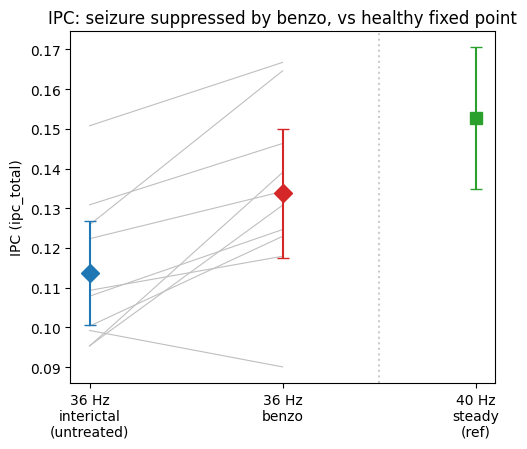

In [13]:
import numpy as np, matplotlib.pyplot as plt
from scipy import stats

a = np.asarray(merged["ctrl_mid"]["ipc_total"], float)      # 36 Hz interictal
b = np.asarray(merged["benzo_steady"]["ipc_total"], float)  # 36 Hz benzo (paired)
s = np.asarray(merged["ctrl_steady"]["ipc_total"], float)   # 40 Hz steady (ref)

def mci(x):
    n=len(x); m=x.mean(); h=stats.t.ppf(.975,n-1)*x.std(ddof=1)/np.sqrt(n); return m,h

fig, ax = plt.subplots(figsize=(5.2, 4.6))
# paired 36 Hz: interictal -> benzo
for ai, bi in zip(a, b):
    ax.plot([0,1],[ai,bi], color='0.75', lw=.8, zorder=1)
for x,arr,col in [(0,a,'tab:blue'),(1,b,'tab:red')]:
    m,h = mci(arr); ax.errorbar(x,m,yerr=h,fmt='D',color=col,ms=9,capsize=4,zorder=3)
# 40 Hz steady reference (unpaired, different freq)
m,h = mci(s); ax.errorbar(2.0,m,yerr=h,fmt='s',color='tab:green',ms=9,capsize=4)

ax.set_xticks([0,1,2])
ax.set_xticklabels(["36 Hz\ninterictal\n(untreated)","36 Hz\nbenzo","40 Hz\nsteady\n(ref)"])
ax.set_ylabel("IPC (ipc_total)")
ax.set_title("IPC: seizure suppressed by benzo, vs healthy fixed point")
ax.axvline(1.5, ls=':', color='0.8')   # visual divider: paired | reference
plt.tight_layout(); plt.show()

In [14]:
st2 = HSP_Phase.paired_phase_stats(merged, metric="ipc_total",
        contrasts=[("benzo_steady","ctrl_mid")])   # note: keys that EXIST
print(st2["contrasts"])   # mean_diff, lo, hi, p_wilcoxon

{'benzo_steady-ctrl_mid': {'mean_diff': 0.020006127842237625, 'sd': 0.015825842217792114, 'sem': 0.00500457072986736, 'lo': 0.008685002319224266, 'hi': 0.03132725336525098, 'n': 10, 'p_ttest': 0.0031218478437965284, 'p_wilcoxon': 0.005859375}}


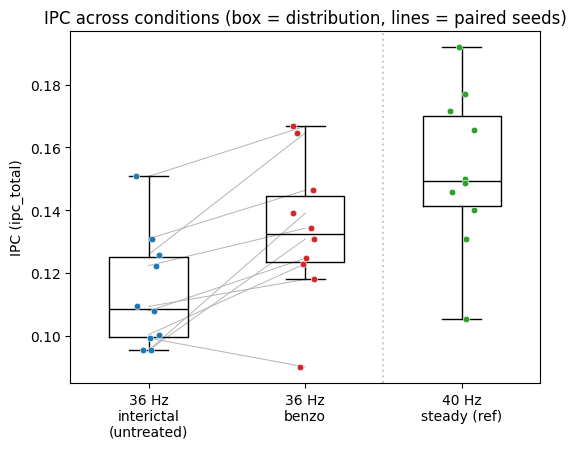

In [15]:
import numpy as np, matplotlib.pyplot as plt
from scipy import stats

a = np.asarray(merged["ctrl_mid"]["ipc_total"], float)      # 36 Hz interictal
b = np.asarray(merged["benzo_steady"]["ipc_total"], float)  # 36 Hz benzo (paired)
s = np.asarray(merged["ctrl_steady"]["ipc_total"], float)   # 40 Hz steady (ref)

fig, ax = plt.subplots(figsize=(5.6, 4.6))
data = [a, b, s]; xs = [1, 2, 3]
ax.boxplot(data, positions=xs, widths=0.5, showfliers=False,
           medianprops=dict(color='k'))

# paired seed lines for the two 36 Hz conditions only
for ai, bi in zip(a, b):
    ax.plot([1, 2], [ai, bi], color='0.7', lw=.7, zorder=1)
# jittered per-seed points
rng = np.random.default_rng(0)
for x, arr, col in [(1, a, 'tab:blue'), (2, b, 'tab:red'), (3, s, 'tab:green')]:
    ax.scatter(np.full(len(arr), x) + rng.uniform(-.08, .08, len(arr)),
               arr, s=22, color=col, zorder=3, edgecolor='w', linewidth=.4)

ax.axvline(2.5, ls=':', color='0.8')
ax.set_xticks(xs)
ax.set_xticklabels(["36 Hz\ninterictal\n(untreated)", "36 Hz\nbenzo",
                    "40 Hz\nsteady (ref)"])
ax.set_ylabel("IPC (ipc_total)")
ax.set_title("IPC across conditions (box = distribution, lines = paired seeds)")
plt.tight_layout(); plt.show()

In [18]:
np.savez('benzo_boxplot.npz',
         **{k: v['ipc_total'] for k, v in merged.items()})   # per-condition IPC arrays

## compare interventions

In [ ]:
interventions = [
    {"name": "untreated",        "drug": {}},
    {"name": "benzo (k=0.7)",    "drug": {"benzo": True, "benzo_kGABA": 0.7}},
    {"name": "benzo (k=1.0)",    "drug": {"benzo": True, "benzo_kGABA": 1.0}},
    {"name": "Na-blocker",       "drug": {"na_blocker": True, "na_vthr_mV": -48,
                                          "na_refrac_ms": 3.0}},
    {"name": "Na + low benzo",   "drug": {"na_blocker": True, "na_vthr_mV": -48,
                                          "benzo": True, "benzo_kGABA": 0.7}},
]
summary = intervention_comparison(net, interventions, f_seizure,
                                  amp_hz=AMP_STAR, step_s=STEP_S, n_steps=2000)

print(f"\n{'intervention':18}{'seizing':>8}{'recov':>7}{'seizPow':>9}"
      f"{'IPC':>6}{'IPCret':>8}{'multiI':>8}{'E/I':>6}{'score':>7}")
for s in summary:                                   # already sorted best-first
    print(f"{s['name']:18}{str(s['is_bursting']):>8}{s['recovery_s']:7.0f}"
          f"{s['cycle_lf_power']:9.2f}{s['ipc_ref']:6.2f}{s['ipc_retained']:8.2f}"
          f"{s['multi_information']:8.2f}{s['EI_ratio']:6.2f}{s['tradeoff_score']:7.3f}")

# trade-off scatter: capacity vs seizure power (top-left = best)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for s in summary:
    ax.scatter(s["cycle_lf_power"], s["ipc_ref"], s=70)
    ax.annotate(s["name"], (s["cycle_lf_power"], s["ipc_ref"]),
                fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("seizure power (cycle low-freq power) -- lower better")
ax.set_ylabel("interictal IPC -- higher better")
ax.set_title("Intervention trade-off: capacity vs seizure (top-left wins)")
ax.grid(alpha=.3); fig.tight_layout(); plt.show()